In [16]:
import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt


In [4]:
PROJECT_DIR = Path.cwd().parent

GROUND_DIR = PROJECT_DIR / "data" / "ground"

station_file = GROUND_DIR / "Station_Locations.csv"

print("Station file:", station_file)
print("File exists:", station_file.exists())

Station file: C:\Users\Asini Perera\CP Lab 1\CP Lab 2\Sri Lanka Rain Fall Reserach\data\ground\Station_Locations.csv
File exists: True


In [7]:
#Reading the coddinates
stations = pd.read_csv(station_file)

print("Number of stations:", len(stations))

display(stations)
print("Column names:", stations.columns.tolist())

Number of stations: 16


,Station,Longitude,Latitude,Elevation,Zone
0,Anuradhapura,80.38,8.33,92.5,dry
1,Badulla,81.05,6.98,669.6,Inter
2,Bandarawela,80.97,6.82,1220.0,Inter
3,Batticaloa,81.70,7.72,2.7,dry
4,Colombo,79.87,6.90,7.3,wet
5,Galle,80.22,6.03,12.5,wet
6,Hambantota,81.13,6.12,15.5,dry
7,Jaffna,80.02,9.65,10.0,dry
8,Kandy,80.63,7.33,477.0,wet
9,Kurunegala,80.35,7.47,116.1,inter


Column names: ['Station', 'Longitude', 'Latitude', 'Elevation', 'Zone']


In [9]:
#select the stations we want
selected_names = [
    "Badulla",
    "Colombo",
    "Galle",
    "Kandy",
    "Nuwara Eliya",
    "Puttalam"
]

selected_stations = stations[stations["Station"].isin(selected_names)].copy()
display(selected_stations)

print("Selected stations:", len(selected_stations))

,Station,Longitude,Latitude,Elevation,Zone
1,Badulla,81.05,6.98,669.6,Inter
4,Colombo,79.87,6.90,7.3,wet
5,Galle,80.22,6.03,12.5,wet
8,Kandy,80.63,7.33,477.0,wet
12,Nuwara Eliya,80.77,6.97,1894.6,wet
13,Puttalam,79.83,8.03,2.1,dry


Selected stations: 6



You should obtain exactly **6 rows**.

### Step 4.2.2 — Create your first JavaScript file

We're going to create a tiny script that displays the six station locations in Google Earth Engine. **No rainfall extraction yet.**

You don't need to type the coordinates manually. We'll use Python to generate the JavaScript from your CSV.

First, create this helper function:


In [12]:
#Creating a helper function
import json

def station_to_feature(row):
    return {
        "type": "Feature",
        "geometry": {
            "type": "Point",
            "coordinates": [
                float(row["Longitude"]),
                float(row["Latitude"])
            ]
        },
        "properties": {
            "Station": row["Station"],
            "Elevation_m": float(row["Elevation"])
        }
    }

In [14]:
#Creating the Java Script file
features = [
    station_to_feature(row)
    for _, row in selected_stations.iterrows()
]

geojson = {
    "type": "FeatureCollection",
    "features": features
}

script = f"""
// Sri Lanka CHIRPS Calibration Project
// Step 4.2: Display the six selected rainfall stations

var stations = ee.FeatureCollection(
    {json.dumps(geojson, indent=2)}
);

Map.centerObject(stations, 8);

Map.addLayer(
    stations,
    {{color: 'red'}},
    'Rainfall stations'
);

print('Number of stations:', stations.size());
print('Station locations:', stations);
"""

script_path = PROJECT_DIR / "scripts" / "export_chirps.js"
script_path.parent.mkdir(parents=True, exist_ok=True)
script_path.write_text(script, encoding="utf-8")

print("JavaScript file created:", script_path)

JavaScript file created: C:\Users\Asini Perera\CP Lab 1\CP Lab 2\Sri Lanka Rain Fall Reserach\scripts\export_chirps.js


In [18]:
#PROJECT_DIR = Path.cwd().parent

CHIRPS_DIR = PROJECT_DIR / "data" / "chirps"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

chirps_file = CHIRPS_DIR / "Six_Stations_CHIRPS_Daily_1981_2000.csv"

print("File exists:", chirps_file.exists())
print("File location:", chirps_file)

File exists: True
File location: C:\Users\Asini Perera\CP Lab 1\CP Lab 2\Sri Lanka Rain Fall Reserach\data\chirps\Six_Stations_CHIRPS_Daily_1981_2000.csv


In [20]:
#Read the CHIRPS data
chirps = pd.read_csv(chirps_file)

print("Dataset shape:", chirps.shape)
print("Column names:", chirps.columns.tolist())

display(chirps.head(10))

Dataset shape: (43830, 3)
Column names: ['Date', 'Station', 'CHIRPS_mm']


,Date,Station,CHIRPS_mm
0,1981-01-01,Badulla,58.288452
1,1981-01-01,Colombo,47.126862
2,1981-01-01,Galle,67.559135
3,1981-01-01,Kandy,36.852249
4,1981-01-01,Nuwara Eliya,62.751240
5,1981-01-01,Puttalam,16.827959
6,1981-01-02,Badulla,17.188242
7,1981-01-02,Colombo,0.000000
8,1981-01-02,Galle,0.000000
9,1981-01-02,Kandy,40.288689


In [22]:
#Convert the columns into correct types
chirps["Date"] = pd.to_datetime(chirps["Date"],errors="coerce") #converts to python dat and time
chirps["CHIRPS_mm"] = pd.to_numeric(chirps["CHIRPS_mm"], errors="coerce") #assure all values are numerical

print("First date:", chirps["Date"].min())
print("Last date:", chirps["Date"].max())

print("Missing dates:", chirps["Date"].isna().sum())
print("Missing rainfall:", chirps["CHIRPS_mm"].isna().sum())
print("Duplicate station-dates:",chirps.duplicated(["Station", "Date"]).sum())

First date: 1981-01-01 00:00:00
Last date: 2000-12-31 00:00:00
Missing dates: 0
Missing rainfall: 0
Duplicate station-dates: 0


In [24]:
#Check station coverage
coverage = chirps.groupby("Station").agg(
    First_Date=("Date", "min"),
    Last_Date=("Date", "max"),
    Total_Days=("Date", "size"),
    Valid_Days=("CHIRPS_mm", "count")
)

coverage["Missing_Days"] = (coverage["Total_Days"] - coverage["Valid_Days"])

display(coverage)

,First_Date,Last_Date,Total_Days,Valid_Days,Missing_Days
Station,,,,,
Badulla,1981-01-01,2000-12-31,7305,7305,0
Colombo,1981-01-01,2000-12-31,7305,7305,0
Galle,1981-01-01,2000-12-31,7305,7305,0
Kandy,1981-01-01,2000-12-31,7305,7305,0
Nuwara Eliya,1981-01-01,2000-12-31,7305,7305,0
Puttalam,1981-01-01,2000-12-31,7305,7305,0


In [26]:
#Match CHIRPS with ground rainfall
#Load the cleaned ground dataset
ground = pd.read_csv(PROCESSED_DIR / "All_Stations_Ground_Cleaned.csv",parse_dates=["Date"])

print("Ground records:", len(ground))
print("CHIRPS records:", len(chirps))

Ground records: 43830
CHIRPS records: 43830


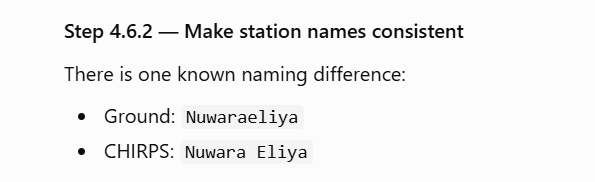

In [29]:
#Make station names consistent
chirps["Station"] = chirps["Station"].str.strip()

chirps["Station"] = chirps["Station"].replace({
    "Nuwara Eliya": "Nuwaraeliya"
})

ground["Station"] = ground["Station"].str.strip()

In [31]:
#Merge Data Sets
comparison = pd.merge(ground,chirps[["Date", "Station", "CHIRPS_mm"]],on=["Date", "Station"],how="left",validate="one_to_one")
comparison = comparison.sort_values(["Station", "Date"]).reset_index(drop=True)

display(comparison.head(10))

print("Total ground records:", len(comparison))
print("Ground missing values:",
      comparison["Rainfall_mm"].isna().sum())
print("CHIRPS missing values:",
      comparison["CHIRPS_mm"].isna().sum())

,Date,Station,Original_Value,Rainfall_mm,QC_Flag,CHIRPS_mm
0,1981-01-01,Badulla,12.4,12.4,Valid,58.288452
1,1981-01-02,Badulla,16.4,16.4,Valid,17.188242
2,1981-01-03,Badulla,37.2,37.2,Valid,9.529316
3,1981-01-04,Badulla,6.4,6.4,Valid,6.546365
4,1981-01-05,Badulla,.0T,0.0,Trace,0.000000
5,1981-01-06,Badulla,0,0.0,Valid,0.000000
6,1981-01-07,Badulla,0,0.0,Valid,0.000000
7,1981-01-08,Badulla,0,0.0,Valid,0.000000
8,1981-01-09,Badulla,0,0.0,Valid,0.000000
9,1981-01-10,Badulla,0,0.0,Valid,0.000000


Total ground records: 43830
Ground missing values: 93
CHIRPS missing values: 0


In [33]:
#Count Valid pair of observations
comparison["Valid_Pair"] = (comparison["Rainfall_mm"].notna() &comparison["CHIRPS_mm"].notna())
pair_summary = comparison.groupby("Station").agg(Total_Days=("Date", "size"),Valid_Pairs=("Valid_Pair", "sum"))
pair_summary["Unpaired_Days"] = (pair_summary["Total_Days"] - pair_summary["Valid_Pairs"])

display(pair_summary)

,Total_Days,Valid_Pairs,Unpaired_Days
Station,,,
Badulla,7305,7300,5
Colombo,7305,7279,26
Galle,7305,7291,14
Kandy,7305,7296,9
Nuwaraeliya,7305,7278,27
Puttalam,7305,7293,12


In [35]:
#Saved Merged Valid Data Set
comparison.to_csv(PROCESSED_DIR / "Ground_CHIRPS_Paired_1981_2000.csv",index=False)
pair_summary.to_csv( PROJECT_DIR / "results" / "CHIRPS_Pair_Coverage.csv")

print("Both files saved successfully.")

Both files saved successfully.


In [37]:
#reusable comparison function - function makes it easy to choose any station and date range.
def get_station_comparison(station, start_date, end_date):

    data = comparison[
        (comparison["Station"] == station) &
        (comparison["Date"].between(
            pd.Timestamp(start_date),
            pd.Timestamp(end_date)
        ))
    ].copy()

    return data.sort_values("Date")

In [39]:
#Plot daily rainfall comparison
def plot_daily_comparison(station, start_date, end_date):

    data = get_station_comparison(station, start_date, end_date)
    if data.empty:
        print("No data available for this selection.")
        return
    plt.figure(figsize=(14, 5))

    plt.plot( data["Date"],data["Rainfall_mm"], "o-", markersize=3, label="Ground station")
    plt.plot(data["Date"],data["CHIRPS_mm"], "s--", markersize=3, label="CHIRPS")

    plt.title(f"{station}: Daily Ground vs CHIRPS")
    plt.xlabel("Date")
    plt.ylabel("Daily rainfall (mm)")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

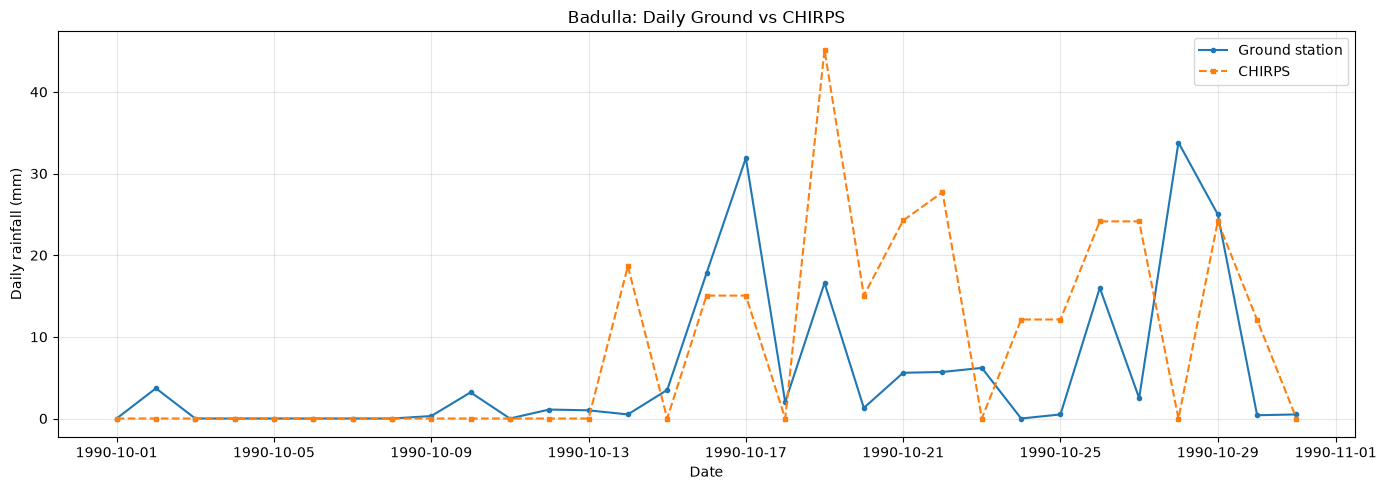

In [41]:
plot_daily_comparison("Badulla","1990-10-01","1990-10-31")

In [43]:
#Plot monthly rainfall comparison
#We will retain all valid daily observations, including those from incomplete months
def plot_monthly_comparison(station, start_date, end_date):

    data = get_station_comparison(station, start_date, end_date )

    # Only dates with valid ground and satellite rainfall
    paired = data.dropna(subset=["Rainfall_mm", "CHIRPS_mm"]).copy()

    if paired.empty:
        print("No valid paired observations.")
        return

    paired = paired.set_index("Date")
    monthly = paired[ ["Rainfall_mm", "CHIRPS_mm"]].resample("MS").sum(min_count=1)
    monthly.plot(
        figsize=(14, 5),
        marker="o",
        title=f"{station}: Monthly Ground vs CHIRPS"
    )

    plt.xlabel("Date")
    plt.ylabel("Rainfall on paired days (mm)")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

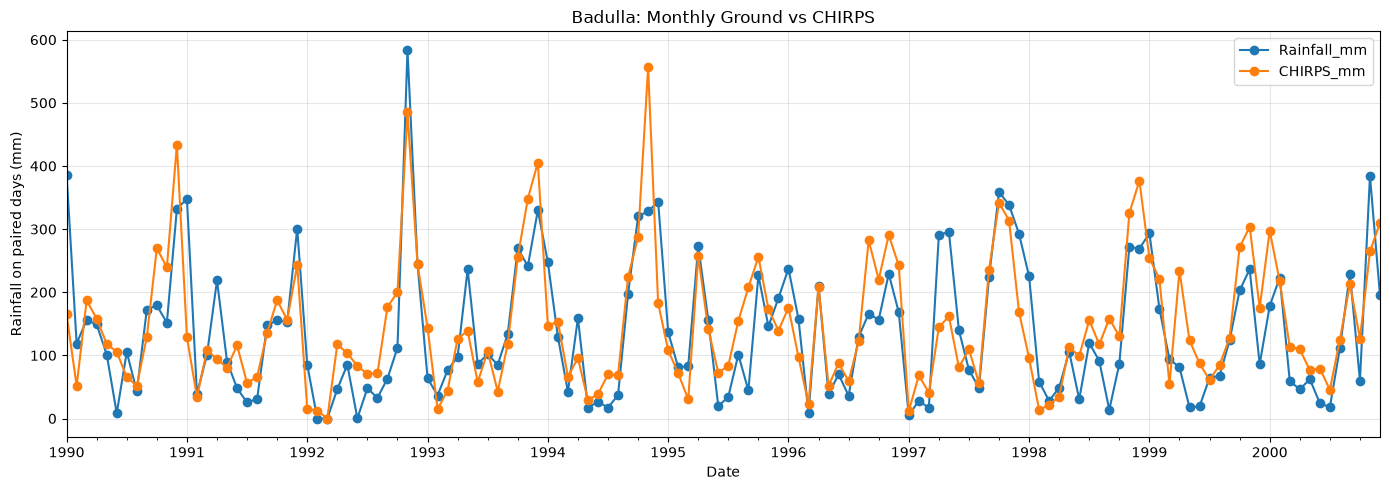

In [45]:
plot_monthly_comparison("Badulla","1990-01-01","2000-12-31")


### Statistical Metrics for Comparing CHIRPS and Ground Rainfall

| Metric | Meaning | Better result |
|--------|---------|---------------|
| Bias | Average CHIRPS − ground rainfall | Closer to 0 |
| MAE | Average absolute error | Smaller |
| RMSE | Root mean squared error | Smaller |
| Pearson correlation | Strength of linear association | Closer to +1 |

The mathematical definitions are:

**1. Bias**

$$
\text{Bias} = \frac{1}{N}\sum_{i=1}^{N}(S_i-G_i)
$$

**2. Mean Absolute Error (MAE)**

$$
\text{MAE} = \frac{1}{N}\sum_{i=1}^{N}|S_i-G_i|
$$

**3. Root Mean Squared Error (RMSE)**

$$
\text{RMSE} = \sqrt{\frac{1}{N}\sum_{i=1}^{N}(S_i-G_i)^2}
$$

**Where:**

- $S_i$ = CHIRPS rainfall for observation $i$.
- $G_i$ = Ground-station rainfall for observation $i$.
- $N$ = Total number of matched observations with valid rainfall values.

**Interpretation:**

- **Bias = 0:** No average systematic overestimation or underestimation.
- **Positive Bias:** CHIRPS overestimates ground rainfall on average.
- **Negative Bias:** CHIRPS underestimates ground rainfall on average.
- **MAE:** Average magnitude of rainfall errors, regardless of direction.
- **RMSE:** Measures prediction differences while giving greater weight to large errors.
- **Pearson correlation (r):** Measures the strength and direction of the linear relationship between CHIRPS and ground rainfall.

**Note:** Bias, MAE, and RMSE have the same units as rainfall (mm), while Pearson correlation is dimensionless and ranges from -1 to +1.


In [48]:
#Calculate baseline performance statistics
def calculate_metrics(data):
    paired = data.dropna(subset=["Rainfall_mm", "CHIRPS_mm"]).copy()

    if paired.empty:
        return {
            "Valid_Days": 0,
            "Bias": np.nan,
            "MAE": np.nan,
            "RMSE": np.nan,
            "Correlation": np.nan
        }

    observed = paired["Rainfall_mm"].to_numpy()
    predicted = paired["CHIRPS_mm"].to_numpy()

    error = predicted - observed

    return {
        "Valid_Days": len(paired),
        "Bias": np.mean(error),
        "MAE": np.mean(np.abs(error)),
        "RMSE": np.sqrt(np.mean(error ** 2)),
        "Correlation": (
            np.corrcoef(observed, predicted)[0, 1]
            if np.std(observed) > 0 and np.std(predicted) > 0
            else np.nan
        )
    }

In [50]:
#Evaluate all six stations
baseline_results = []

for station in sorted(comparison["Station"].unique()):
    station_data = comparison[comparison["Station"] == station]
    metrics = calculate_metrics(station_data)
    metrics["Station"] = station

    baseline_results.append(metrics)

baseline_summary = pd.DataFrame(baseline_results)

baseline_summary = baseline_summary[
    ["Station", "Valid_Days",
     "Bias", "MAE", "RMSE", "Correlation"]
]

display(baseline_summary.round(3))

,Station,Valid_Days,Bias,MAE,RMSE,Correlation
0,Badulla,7300,-0.093,5.575,11.971,0.393
1,Colombo,7279,-0.745,7.024,15.791,0.398
2,Galle,7291,-0.740,7.216,15.575,0.388
3,Kandy,7296,0.103,6.353,12.876,0.320
4,Nuwaraeliya,7278,0.479,6.688,13.048,0.342
5,Puttalam,7293,-0.463,3.748,10.971,0.397


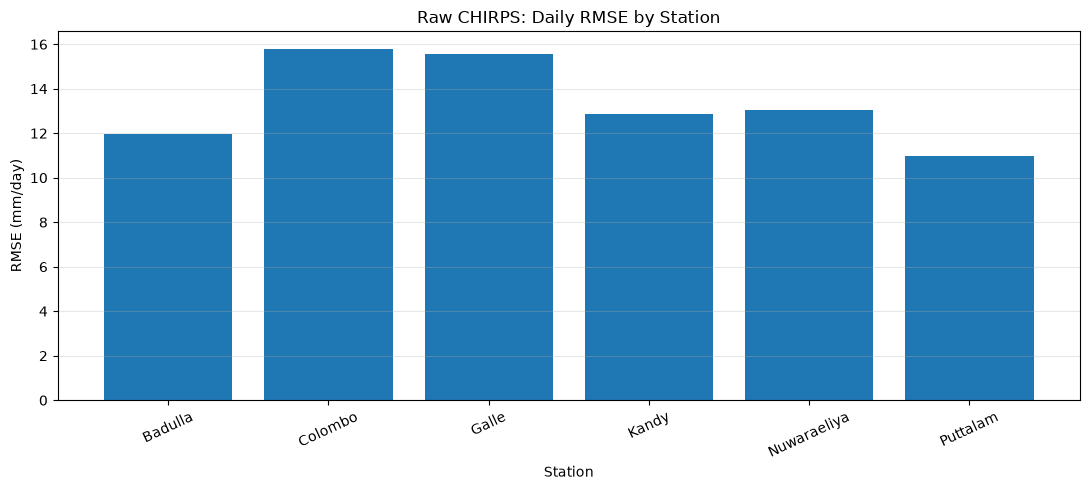

In [52]:
#Plot the baseline error for all stations
fig, ax = plt.subplots(figsize=(11, 5))

ax.bar( baseline_summary["Station"], baseline_summary["RMSE"])
ax.set_title("Raw CHIRPS: Daily RMSE by Station")
ax.set_xlabel("Station")
ax.set_ylabel("RMSE (mm/day)")
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

In [54]:
#compare station-level errors by rainfall intensity.
def rainfall_intensity_analysis(station):

    data = comparison[comparison["Station"] == station].dropna(
        subset=["Rainfall_mm", "CHIRPS_mm"]
    ).copy()

    bins = [-0.001, 0, 1, 10, 25, np.inf]
    labels = ["Dry", "0–1", "1–10", "10–25", ">25"]

    data["Intensity"] = pd.cut(
        data["Rainfall_mm"],
        bins=bins,
        labels=labels,
        include_lowest=True
    )

    results = []

    for category in labels:
        subset = data[data["Intensity"] == category] #this gives a category based on ground gauge values not chirp values. 
        if subset.empty:
            continue

        metrics = calculate_metrics(subset)

        results.append({
            "Station": station,
            "Intensity": category,
            "Days": metrics["Valid_Days"],
            "Bias": metrics["Bias"],
            "MAE": metrics["MAE"],
            "RMSE": metrics["RMSE"]
        })

    return pd.DataFrame(results)

In [56]:
badulla_intensity = rainfall_intensity_analysis("Badulla")

display(badulla_intensity.round(3))

,Station,Intensity,Days,Bias,MAE,RMSE
0,Badulla,Dry,4134,1.785,1.785,5.897
1,Badulla,0–1,741,4.248,4.858,10.391
2,Badulla,1–10,1412,2.384,7.021,10.761
3,Badulla,10–25,611,-5.755,12.387,15.303
4,Badulla,>25,402,-27.517,30.425,35.820


In [58]:
#running for every station
intensity_results = pd.concat(
    [
        rainfall_intensity_analysis(station)
        for station in sorted(comparison["Station"].unique())
    ],
    ignore_index=True
)

display(intensity_results.round(3))

,Station,Intensity,Days,Bias,MAE,RMSE
0,Badulla,Dry,4134,1.785,1.785,5.897
1,Badulla,0–1,741,4.248,4.858,10.391
2,Badulla,1–10,1412,2.384,7.021,10.761
3,Badulla,10–25,611,-5.755,12.387,15.303
4,Badulla,>25,402,-27.517,30.425,35.820
5,Colombo,Dry,3884,1.973,1.973,6.016
6,Colombo,0–1,727,4.494,5.073,9.400
7,Colombo,1–10,1466,3.370,8.068,11.959
8,Colombo,10–25,669,-4.521,12.587,15.473
9,Colombo,>25,533,-34.278,36.639,48.243


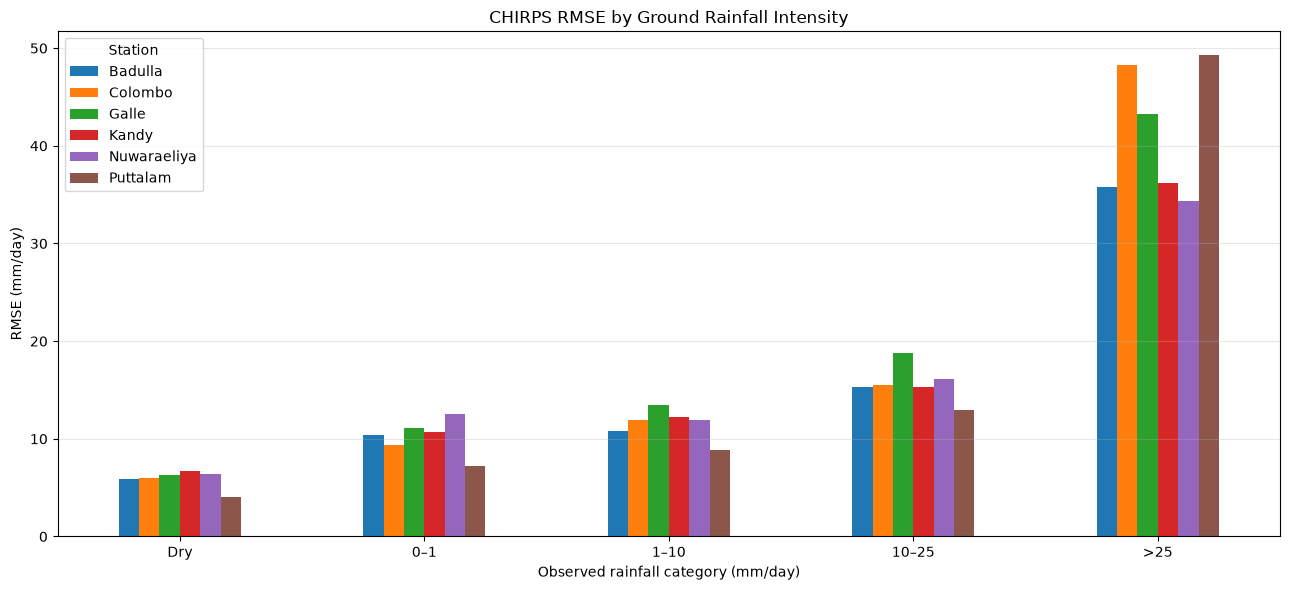

In [60]:
#Plotting RMSE Values
rmse_intensity = intensity_results.pivot(index="Intensity",columns="Station",values="RMSE")
rmse_intensity = rmse_intensity.reindex(  ["Dry", "0–1", "1–10", "10–25", ">25"])
rmse_intensity.plot( kind="bar",figsize=(13, 6))

plt.title("CHIRPS RMSE by Ground Rainfall Intensity")
plt.xlabel("Observed rainfall category (mm/day)")
plt.ylabel("RMSE (mm/day)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

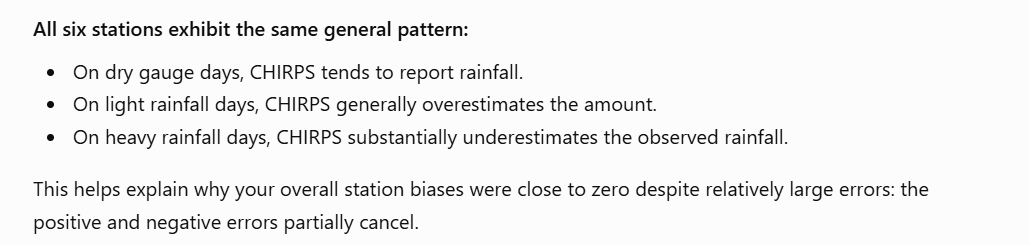

In [63]:
RESULTS_DIR = PROJECT_DIR / "results"

intensity_results.to_csv(RESULTS_DIR / "CHIRPS_Intensity_Analysis.csv",index=False)
print("Intensity analysis saved!")

Intensity analysis saved!


In [65]:
# Save six-station CHIRPS baseline statistics

RESULTS_DIR = PROJECT_DIR / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

baseline_summary.to_csv(RESULTS_DIR / "CHIRPS_Raw_Baseline_Six_Stations.csv",index=False)
print("Baseline statistics saved successfully!")

Baseline statistics saved successfully!
